### 1. Импорты

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
import numpy as np

import json
import platform
import random

import torchvision
from torch import nn

# Определяем корень проекта diplom_project
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    if (PROJECT_ROOT.parent / "src").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError(
            "Не удалось найти папку src. "
            "Открой notebook внутри проекта diplom_project."
        )

# Добавляем корень проекта в путь Python
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import CLASS_NAMES, load_fashion_mnist, create_train_validation_split, calculate_train_mean_std, create_normalized_transform

from src.model import FashionCNN, count_trainable_parameters

print("Корень проекта:", PROJECT_ROOT)
print("Классы:", CLASS_NAMES)

Корень проекта: d:\Учеба\fashion-mnist-cnn-experiments
Классы: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 2. Загрузка датасета

In [2]:
full_train_dataset, test_dataset = load_fashion_mnist()

print("Размер обучающей выборки:", len(full_train_dataset))
print("Размер тестовой выборки:", len(test_dataset))

Размер обучающей выборки: 60000
Размер тестовой выборки: 10000


### 3. Проверка одного изображения

In [3]:
image, label = full_train_dataset[0]

label = int(label)

print("Тип изображения:", type(image))
print("Размер изображения:", image.shape)
print("Тип данных:", image.dtype)
print("Минимальное значение:", image.min().item())
print("Максимальное значение:", image.max().item())
print("Числовая метка:", label)
print("Название класса:", CLASS_NAMES[label])

assert image.shape == (1, 28, 28)
assert 0 <= label < 10
assert image.min() >= 0
assert image.max() <= 1

print("Проверка изображения пройдена")

Тип изображения: <class 'torch.Tensor'>
Размер изображения: torch.Size([1, 28, 28])
Тип данных: torch.float32
Минимальное значение: 0.0
Максимальное значение: 1.0
Числовая метка: 9
Название класса: Ankle boot
Проверка изображения пройдена


### 4. Проверка количества классов

In [4]:
print("Классы из датасета:")
print(full_train_dataset.classes)

print()
print("Наш список классов:")
print(CLASS_NAMES)

assert len(full_train_dataset.classes) == 10
assert full_train_dataset.classes == CLASS_NAMES

unique_labels = torch.unique(full_train_dataset.targets).tolist()

print("Уникальные метки:", unique_labels)

assert unique_labels == list(range(10))

Классы из датасета:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Наш список классов:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Уникальные метки: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


### 5. Количество изображений каждого класса

In [5]:
train_labels = full_train_dataset.targets
test_labels = test_dataset.targets

train_counts = torch.bincount(
    train_labels,
    minlength=len(CLASS_NAMES),
)

test_counts = torch.bincount(
    test_labels,
    minlength=len(CLASS_NAMES),
)

print("Количество изображений в train:")
for class_id, count in enumerate(train_counts):
    print(f"{class_id}: {CLASS_NAMES[class_id]} — {int(count)}")

print()
print("Количество изображений в test:")
for class_id, count in enumerate(test_counts):
    print(f"{class_id}: {CLASS_NAMES[class_id]} — {int(count)}")

assert train_counts.sum().item() == 60000
assert test_counts.sum().item() == 10000
assert torch.all(train_counts == 6000)
assert torch.all(test_counts == 1000)

print("Распределение классов проверено")

Количество изображений в train:
0: T-shirt/top — 6000
1: Trouser — 6000
2: Pullover — 6000
3: Dress — 6000
4: Coat — 6000
5: Sandal — 6000
6: Shirt — 6000
7: Sneaker — 6000
8: Bag — 6000
9: Ankle boot — 6000

Количество изображений в test:
0: T-shirt/top — 1000
1: Trouser — 1000
2: Pullover — 1000
3: Dress — 1000
4: Coat — 1000
5: Sandal — 1000
6: Shirt — 1000
7: Sneaker — 1000
8: Bag — 1000
9: Ankle boot — 1000
Распределение классов проверено


### 6. График распределения классов

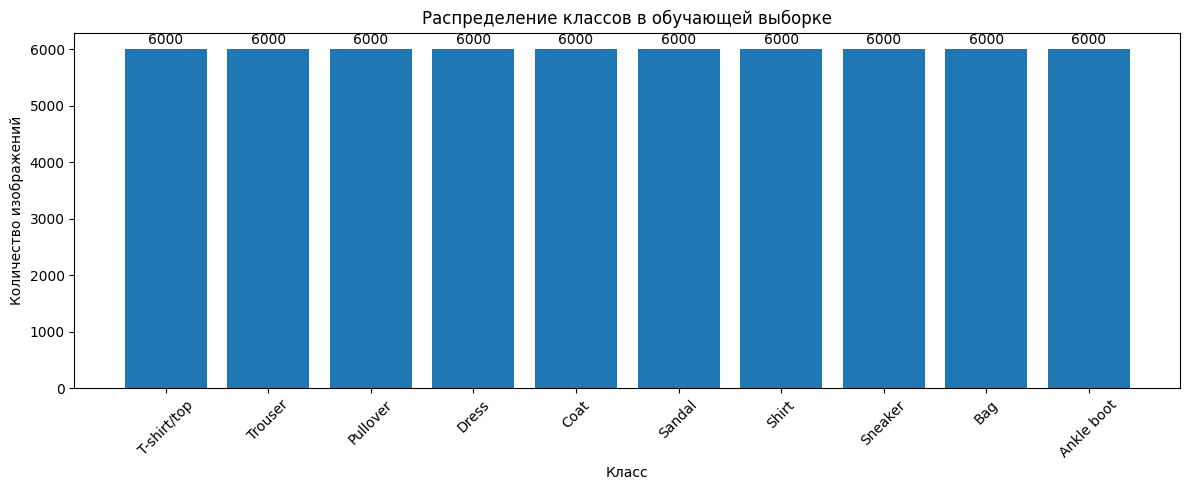

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(CLASS_NAMES, train_counts.numpy())

ax.set_title("Распределение классов в обучающей выборке")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество изображений")
ax.tick_params(axis="x", rotation=45)

for bar, count in zip(bars, train_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        str(int(count)),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

### 7. Сетка первых 16 изображений

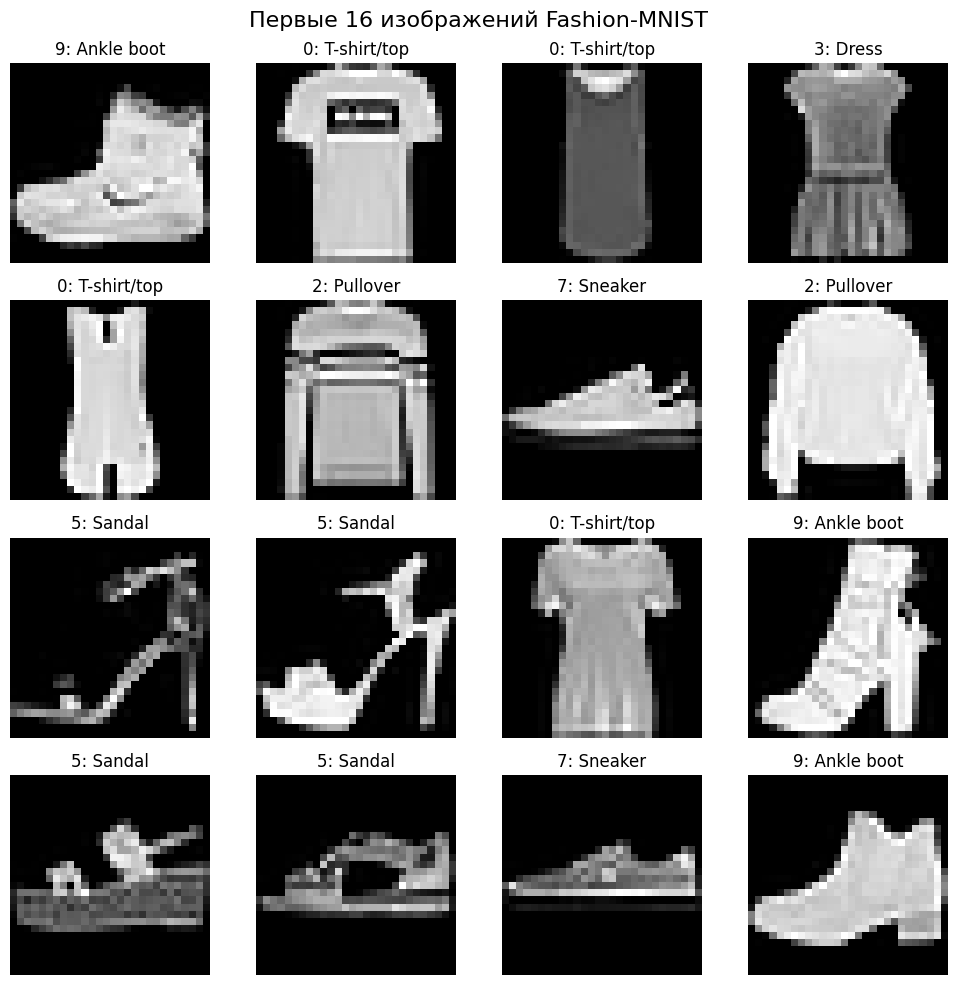

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for index, ax in enumerate(axes.ravel()):
    image, label = full_train_dataset[index]
    label = int(label)

    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"{label}: {CLASS_NAMES[label]}")
    ax.axis("off")

fig.suptitle("Первые 16 изображений Fashion-MNIST", fontsize=16)
plt.tight_layout()
plt.show()

### 8. Случайные изображения

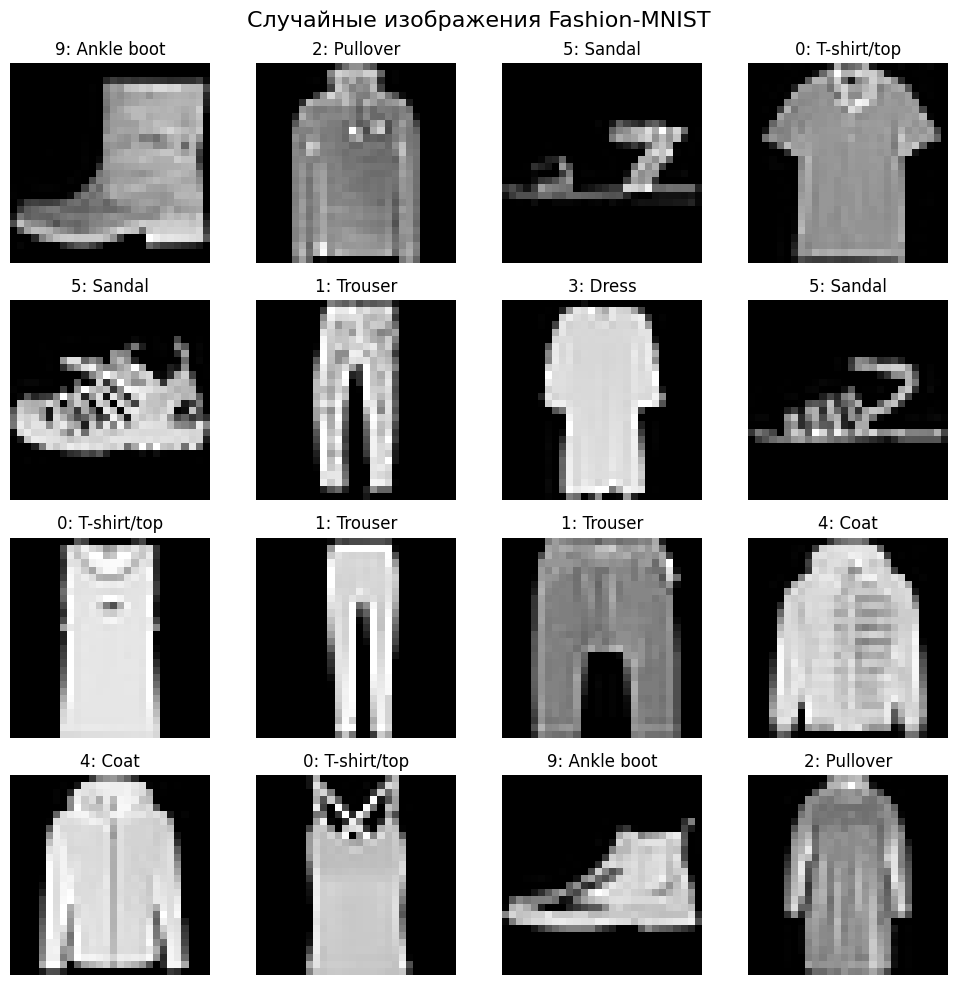

In [8]:
generator = torch.Generator()
generator.manual_seed(42)

random_indices = torch.randperm(
    len(full_train_dataset),
    generator=generator,
)[:16].tolist()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for ax, index in zip(axes.ravel(), random_indices):
    image, label = full_train_dataset[index]
    label = int(label)

    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"{label}: {CLASS_NAMES[label]}")
    ax.axis("off")

fig.suptitle("Случайные изображения Fashion-MNIST", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:
print("Проверка этапа 3 завершена")
print(f"Train: {len(full_train_dataset)} изображений")
print(f"Test: {len(test_dataset)} изображений")
print(f"Размер одного изображения: {full_train_dataset[0][0].shape}")
print(f"Количество классов: {len(CLASS_NAMES)}")

Проверка этапа 3 завершена
Train: 60000 изображений
Test: 10000 изображений
Размер одного изображения: torch.Size([1, 28, 28])
Количество классов: 10


### 9. Разделение на train и validation 

In [10]:
train_dataset, validation_dataset, train_indices, validation_indices = (
    create_train_validation_split(
        full_train_dataset,
        validation_fraction=0.10,
        seed=42,
    )
)

print("Размер train:", len(train_dataset))
print("Размер validation:", len(validation_dataset))
print("Размер test:", len(test_dataset))

Используется сохранённое разбиение.
Размер train: 54000
Размер validation: 6000
Размер test: 10000


In [11]:
## Проверка, что индексы не пересекаются
intersection = np.intersect1d(
    train_indices,
    validation_indices,
)

union = np.union1d(
    train_indices,
    validation_indices,
)

print("Количество общих индексов:", len(intersection))
print("Количество уникальных индексов:", len(union))

assert len(intersection) == 0
assert len(union) == len(full_train_dataset)

print("Train и validation не пересекаются.")

Количество общих индексов: 0
Количество уникальных индексов: 60000
Train и validation не пересекаются.


In [12]:
## Проверка распределения классов
full_targets = full_train_dataset.targets.cpu().numpy()

train_class_counts = np.bincount(
    full_targets[train_indices],
    minlength=10,
)

validation_class_counts = np.bincount(
    full_targets[validation_indices],
    minlength=10,
)

test_targets = test_dataset.targets.cpu().numpy()

test_class_counts = np.bincount(
    test_targets,
    minlength=10,
)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_id}: {class_name:12} | "
        f"train={train_class_counts[class_id]:4} | "
        f"validation={validation_class_counts[class_id]:4} | "
        f"test={test_class_counts[class_id]:4}"
    )

assert train_class_counts.sum() == 54000
assert validation_class_counts.sum() == 6000
assert test_class_counts.sum() == 10000

0: T-shirt/top  | train=5400 | validation= 600 | test=1000
1: Trouser      | train=5400 | validation= 600 | test=1000
2: Pullover     | train=5400 | validation= 600 | test=1000
3: Dress        | train=5400 | validation= 600 | test=1000
4: Coat         | train=5400 | validation= 600 | test=1000
5: Sandal       | train=5400 | validation= 600 | test=1000
6: Shirt        | train=5400 | validation= 600 | test=1000
7: Sneaker      | train=5400 | validation= 600 | test=1000
8: Bag          | train=5400 | validation= 600 | test=1000
9: Ankle boot   | train=5400 | validation= 600 | test=1000


### 10. Нормализация

In [13]:
mean, std = calculate_train_mean_std(
    full_train_dataset=full_train_dataset,
    train_indices=train_indices,
)

print("Среднее значение train:", mean)
print("Стандартное отклонение train:", std)

Среднее значение train: 0.28620901279348543
Стандартное отклонение train: 0.3531597507360165


In [14]:
normalized_transform = create_normalized_transform(
    mean=mean,
    std=std,
)

full_train_dataset.transform = normalized_transform
test_dataset.transform = normalized_transform

In [15]:
train_image, train_label = train_dataset[0]
validation_image, validation_label = validation_dataset[0]
test_image, test_label = test_dataset[0]

print("Размер train image:", train_image.shape)
print("Размер validation image:", validation_image.shape)
print("Размер test image:", test_image.shape)

print()
print("Train image:")
print("min:", train_image.min().item())
print("max:", train_image.max().item())
print("mean:", train_image.mean().item())
print("std:", train_image.std().item())

Размер train image: torch.Size([1, 28, 28])
Размер validation image: torch.Size([1, 28, 28])
Размер test image: torch.Size([1, 28, 28])

Train image:
min: -0.8104236721992493
max: 2.021156072616577
mean: 0.2695055902004242
std: 1.1310476064682007


In [16]:
from torch.utils.data import DataLoader

train_loader_for_check = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=False,
)

normalized_sum = 0.0
normalized_squared_sum = 0.0
normalized_count = 0

for images, labels in train_loader_for_check:
    normalized_sum += images.sum().item()
    normalized_squared_sum += (images * images).sum().item()
    normalized_count += images.numel()

normalized_mean = normalized_sum / normalized_count

normalized_variance = (
    normalized_squared_sum / normalized_count
    - normalized_mean**2
)

normalized_std = normalized_variance**0.5

print("Среднее после нормализации:", normalized_mean)
print("Стандартное отклонение после нормализации:", normalized_std)

Среднее после нормализации: -3.947908916170635e-08
Стандартное отклонение после нормализации: 0.9999999970474293


In [17]:
import json

config_path = (
    PROJECT_ROOT
    / "configs"
    / "fashion_mnist_baseline.json"
)

if config_path.exists():
    config = json.loads(
        config_path.read_text(encoding="utf-8")
    )
else:
    config = {}

config["normalization"] = {
    "mean": mean,
    "std": std,
    "calculated_from": "train split only",
    "train_size": len(train_indices),
}

config_path.write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print("Значения нормализации сохранены в:", config_path)

Значения нормализации сохранены в: d:\Учеба\fashion-mnist-cnn-experiments\configs\fashion_mnist_baseline.json


### 11. CNN

In [18]:
#Создание модели
model = FashionCNN()

print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [19]:
#Подсчёт параметров
parameter_count = count_trainable_parameters(model)

print("Количество обучаемых параметров:", parameter_count)

Количество обучаемых параметров: 105962


In [20]:
#Проверка формы выхода
batch_size = 4

dummy_images = torch.zeros(
    batch_size,
    1,
    28,
    28,
)

logits = model(dummy_images)

print("Размер входа:", dummy_images.shape)
print("Размер выхода:", logits.shape)

assert dummy_images.shape == (4, 1, 28, 28)
assert logits.shape == (4, 10)
assert parameter_count == 105_962

print("Проверка архитектуры пройдена")

Размер входа: torch.Size([4, 1, 28, 28])
Размер выхода: torch.Size([4, 10])
Проверка архитектуры пройдена


In [21]:
#Проверка с реальным изображением
image, label = train_dataset[0]

print("Размер одного изображения:", image.shape)
print("Метка:", label)

image_batch = image.unsqueeze(0)

print("Размер после добавления batch:", image_batch.shape)

with torch.no_grad():
    logits = model(image_batch)

print("Размер logits:", logits.shape)
print("Logits:", logits)

Размер одного изображения: torch.Size([1, 28, 28])
Метка: 9
Размер после добавления batch: torch.Size([1, 1, 28, 28])
Размер logits: torch.Size([1, 10])
Logits: tensor([[-0.1673, -0.1449, -0.3542, -0.0872, -0.0406, -0.3920,  0.0874,  0.2488,
          0.0062, -0.2956]])


In [22]:
#Получение предварительного предсказания
predicted_class = logits.argmax(dim=1).item()

print("Предсказанный класс:", predicted_class)
print("Настоящий класс:", int(label))

Предсказанный класс: 7
Настоящий класс: 9


### 12. Задание параметров обучения

In [23]:
#Фиксированный SEED
SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Повышает воспроизводимость результатов на GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

print("Seed:", SEED)

Seed: 42


In [24]:
#Выбор устройства
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Устройство:", device)

Устройство: cuda


In [25]:
#Параметры обучения
training_config = {
    "seed": 42,
    "batch_size": 128,

    # Максимальное количество эпох на каждом этапе
    "epochs": 100,

    # Остановка, если Validation Loss
    # не улучшается 10 эпох
    "early_stopping_patience": 10,

    # Минимальное улучшение Validation Loss,
    # которое считается улучшением
    "min_delta": 1e-4,

    "optimizer": "Adam",

    # Первый этап
    "learning_rate": 0.001,

    # На втором этапе:
    # 0.001 * 0.1 = 0.0001
    "learning_rate_factor": 0.1,

    "weight_decay": 0.0001,
    "dropout": 0.3,
    "loss": "CrossEntropyLoss",
    "device": str(device),
}

In [26]:
#Создание модели, функции ошибки и оптимизатора
model = FashionCNN(
    dropout=training_config["dropout"]
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

In [27]:
#Сохранение параметров в конфигурацию
config_path = (
    PROJECT_ROOT
    / "configs"
    / "fashion_mnist_baseline.json"
)

if config_path.exists():
    config = json.loads(
        config_path.read_text(encoding="utf-8")
    )
else:
    config = {}

config["training"] = training_config

config["runtime"] = {
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "device": str(device),
    "trainable_parameters": sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    ),
}

config["dataset_sizes"] = {
    "train": len(train_dataset),
    "validation": len(validation_dataset),
    "test": len(test_dataset),
}

config.setdefault("results", {
    "best_epoch": None,
    "best_validation_accuracy": None,
    "test_accuracy": None,
})

config_path.write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("Конфигурация сохранена в:")
print(config_path)

Конфигурация сохранена в:
d:\Учеба\fashion-mnist-cnn-experiments\configs\fashion_mnist_baseline.json


### 13. Реализация обучения

In [28]:
from torch.utils.data import DataLoader


train_loader = DataLoader(
    train_dataset,
    batch_size=training_config["batch_size"],
    shuffle=True,
    num_workers=0,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

print("Количество train batches:", len(train_loader))
print(
    "Количество validation batches:",
    len(validation_loader),
)

Количество train batches: 422
Количество validation batches: 47


In [29]:
from src.train import fit_two_stage


model = FashionCNN(
    dropout=training_config["dropout"]
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

In [30]:
checkpoint_path = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "checkpoints"
    / "best_model.pt"
)

history_path = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "history.json"
)

In [31]:
normalization_config = {
    "mean": float(mean),
    "std": float(std),
    "calculated_from": "train split only",
}

In [32]:
architecture_config = {
    "name": "FashionCNN",
    "input_shape": [1, 28, 28],
    "num_classes": 10,
    "dropout": float(
        training_config["dropout"]
    ),
    "layers": [
        {
            "type": "Conv2d",
            "in_channels": 1,
            "out_channels": 16,
            "kernel_size": 3,
            "padding": 1,
        },
        {
            "type": "BatchNorm2d",
            "num_features": 16,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "MaxPool2d",
            "kernel_size": 2,
        },
        {
            "type": "Conv2d",
            "in_channels": 16,
            "out_channels": 32,
            "kernel_size": 3,
            "padding": 1,
        },
        {
            "type": "BatchNorm2d",
            "num_features": 32,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "MaxPool2d",
            "kernel_size": 2,
        },
        {
            "type": "Flatten",
        },
        {
            "type": "Linear",
            "in_features": 32 * 7 * 7,
            "out_features": 64,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "Dropout",
            "probability": 0.3,
        },
        {
            "type": "Linear",
            "in_features": 64,
            "out_features": 10,
        },
    ],
}

In [33]:
checkpoint_metadata = {
    "seed": int(training_config["seed"]),
    "normalization": normalization_config,
    "architecture": architecture_config,
    "training": training_config,
    "dataset_sizes": {
        "train": len(train_dataset),
        "validation": len(validation_dataset),
        "test": len(test_dataset),
    },
}

In [34]:
from src.train import fit_two_stage
history = fit_two_stage(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=training_config["epochs"],
    patience=training_config[
        "early_stopping_patience"
    ],
    min_delta=training_config[
        "min_delta"
    ],
    lr_factor=training_config[
        "learning_rate_factor"
    ],
    checkpoint_path=checkpoint_path,
    history_path=history_path,
    checkpoint_metadata=checkpoint_metadata,
)

Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.5062 | train accuracy: 0.8200 | validation loss: 0.2959 | validation accuracy: 0.8933
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.3389 | train accuracy: 0.8796 | validation loss: 0.2835 | validation accuracy: 0.8980
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.2947 | train accuracy: 0.8948 | validation loss: 0.2452 | validation accuracy: 0.9105
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.2744 | train accuracy: 0.9013 | validation loss: 0.2337 | validation accuracy: 0.9112
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.2564 | train accuracy: 0.9068 | validation loss: 0.2281 | validation accuracy: 0.9153
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.2409 | train accuracy: 0.9114 | validation loss: 0.2518 | validation accuracy: 0.9080
Stage 1 | Epoch 007 | lr: 0.001000 | train loss: 0.2305 | train accuracy: 0.9151 | validation loss: 0.2226 | validation accuracy: 0.9210
Stage 1 | Epoch 008 | lr: 0.001000 | trai

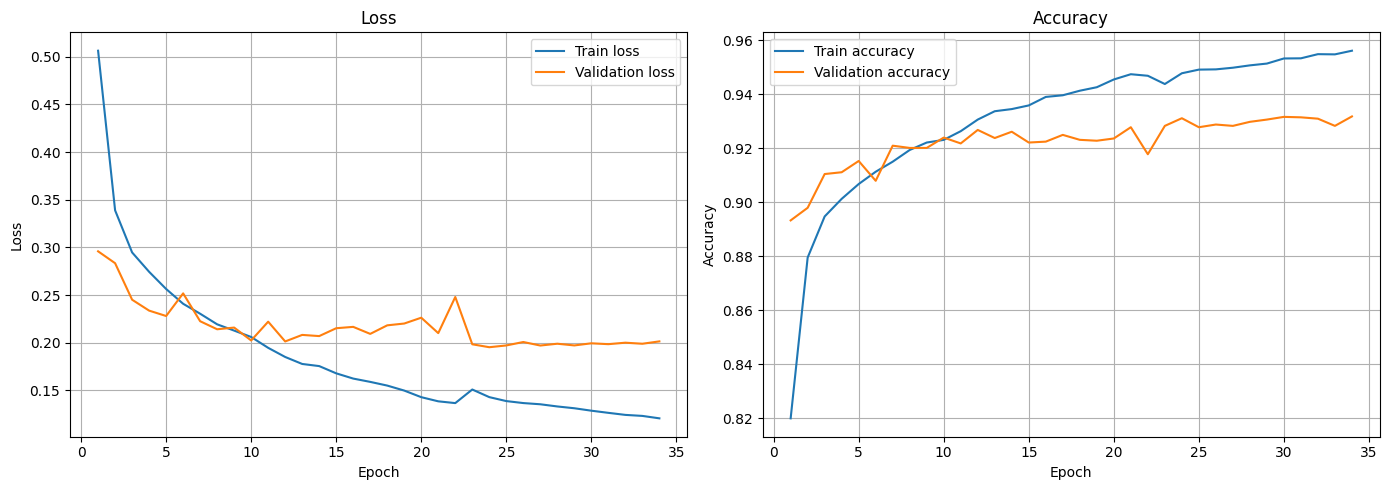

In [35]:
import matplotlib.pyplot as plt


epochs = history["epoch"]

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

# График ошибки
axes[0].plot(
    epochs,
    history["train_loss"],
    label="Train loss",
)

axes[0].plot(
    epochs,
    history["validation_loss"],
    label="Validation loss",
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()


# График accuracy
axes[1].plot(
    epochs,
    history["train_accuracy"],
    label="Train accuracy",
)

axes[1].plot(
    epochs,
    history["validation_accuracy"],
    label="Validation accuracy",
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [36]:
best_index = history["validation_loss"].index(
    min(history["validation_loss"])
)

best_epoch = history["epoch"][best_index]
best_validation_loss = (
    history["validation_loss"][best_index]
)
best_validation_accuracy = (
    history["validation_accuracy"][best_index]
)
best_stage = history["stage"][best_index]

print("Лучшая эпоха по Validation Loss:", best_epoch)
print("Лучший этап:", best_stage)
print("Минимальный Validation Loss:", best_validation_loss)
print("Validation Accuracy на лучшей эпохе:", best_validation_accuracy)
print("В процентах:", best_validation_accuracy * 100)

Лучшая эпоха по Validation Loss: 24
Лучший этап: 2
Минимальный Validation Loss: 0.19537509195009867
Validation Accuracy на лучшей эпохе: 0.9311666666666667
В процентах: 93.11666666666667


In [37]:
#Проверка содержимого checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
)
print(checkpoint.keys())

dict_keys(['epoch', 'stage', 'model_state_dict', 'optimizer_state_dict', 'validation_loss', 'validation_accuracy', 'best_validation_loss', 'history', 'seed', 'normalization', 'architecture', 'training', 'dataset_sizes'])


### 14. Расчёт метрик на test

In [38]:
from torch.utils.data import DataLoader

#Создание test_loader
test_loader = DataLoader(
    test_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

In [39]:
#Загрузка общей модели
import torch
from src.model import FashionCNN


checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
)

saved_training_config = checkpoint.get(
    "training",
    training_config,
)

best_model = FashionCNN(
    dropout=saved_training_config["dropout"]
).to(device)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model.eval()

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [40]:
print("Эпоха модели:", checkpoint["epoch"])
print(
    "Validation accuracy:",
    checkpoint["validation_accuracy"],
)

Эпоха модели: 24
Validation accuracy: 0.9311666666666667


In [41]:
# Предсказания на train, validation и test
import csv
import json
from pathlib import Path

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
)


train_eval_loader = DataLoader(
    train_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)


def collect_predictions(
    model,
    data_loader,
    device,
):
    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)

            logits = model(images)
            predictions = logits.argmax(dim=1)

            all_labels.append(labels.cpu())
            all_predictions.append(predictions.cpu())

    return (
        torch.cat(all_labels).numpy(),
        torch.cat(all_predictions).numpy(),
    )


train_y_true, train_y_pred = collect_predictions(
    model=best_model,
    data_loader=train_eval_loader,
    device=device,
)

validation_y_true, validation_y_pred = collect_predictions(
    model=best_model,
    data_loader=validation_loader,
    device=device,
)

test_y_true, test_y_pred = collect_predictions(
    model=best_model,
    data_loader=test_loader,
    device=device,
)

# Эти имена используются в следующих разделах
y_true = test_y_true
y_pred = test_y_pred

class_ids = np.arange(len(CLASS_NAMES))


def calculate_per_class_metrics(
    y_true,
    y_pred,
):
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=class_ids,
    )

    total_samples = int(matrix.sum())
    rows = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        tp = int(matrix[class_id, class_id])
        fn = int(matrix[class_id, :].sum() - tp)
        fp = int(matrix[:, class_id].sum() - tp)
        tn = int(total_samples - tp - fn - fp)
        support = tp + fn

        recall = tp / support if support > 0 else 0.0
        accuracy = (tp + tn) / total_samples

        rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "recall": float(recall),
            "accuracy": float(accuracy),
            "support": support,
            "true_positive": tp,
            "false_positive": fp,
            "false_negative": fn,
        })

    return matrix, rows


def save_per_class_metrics(rows, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    fieldnames = [
        "class_id",
        "class_name",
        "recall",
        "accuracy",
        "support",
        "true_positive",
        "false_positive",
        "false_negative",
    ]

    with path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)


train_confusion, train_rows = calculate_per_class_metrics(
    train_y_true, train_y_pred
)
validation_confusion, validation_rows = calculate_per_class_metrics(
    validation_y_true, validation_y_pred
)
test_confusion, test_rows = calculate_per_class_metrics(
    test_y_true, test_y_pred
)

# Матрица test используется в разделе 15
confusion = test_confusion

metrics_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "metrics"
)
metrics_dir.mkdir(parents=True, exist_ok=True)

save_per_class_metrics(
    train_rows,
    metrics_dir / "train_per_class_metrics.csv",
)
save_per_class_metrics(
    validation_rows,
    metrics_dir / "validation_per_class_metrics.csv",
)
save_per_class_metrics(
    test_rows,
    metrics_dir / "test_per_class_metrics.csv",
)

overall_accuracy = accuracy_score(test_y_true, test_y_pred)
macro_f1 = f1_score(
    test_y_true,
    test_y_pred,
    average="macro",
    zero_division=0,
)

test_metrics = {
    "experiment": "Full F baseline",
    "train_size": len(train_dataset),
    "validation_size": len(validation_dataset),
    "test_size": len(test_dataset),
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "checkpoint_stage": int(checkpoint["stage"]),
    "validation_loss": float(checkpoint["validation_loss"]),
    "validation_accuracy": float(checkpoint["validation_accuracy"]),
    "test_accuracy": float(overall_accuracy),
    "macro_f1": float(macro_f1),
    "seed": int(SEED),
}

(metrics_dir / "test_metrics.json").write_text(
    json.dumps(test_metrics, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Full F метрики сохранены.")
print("Test accuracy:", overall_accuracy)
print("Macro-F1:", macro_f1)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint stage:", checkpoint["stage"])
print("Validation Loss:", checkpoint["validation_loss"])

Full F метрики сохранены.
Test accuracy: 0.92
Macro-F1: 0.9197469417870059
Checkpoint epoch: 24
Checkpoint stage: 2
Validation Loss: 0.19537509195009867


In [42]:
# Общие метрики рассчитаны и сохранены в предыдущей ячейке.
print("Test accuracy:", overall_accuracy)
print("Macro-F1:", macro_f1)

Test accuracy: 0.92
Macro-F1: 0.9197469417870059


In [43]:
# Recall и Accuracy по классам рассчитаны выше.
for row in test_rows:
    print(
        f"{row['class_name']}: "
        f"Recall={row['recall']:.4f}, "
        f"Accuracy={row['accuracy']:.4f}"
    )

T-shirt/top: Recall=0.8810, Accuracy=0.9737
Trouser: Recall=0.9850, Accuracy=0.9975
Pullover: Recall=0.8680, Accuracy=0.9755
Dress: Recall=0.9210, Accuracy=0.9834
Coat: Recall=0.8910, Accuracy=0.9749
Sandal: Recall=0.9800, Accuracy=0.9967
Shirt: Recall=0.7460, Accuracy=0.9538
Sneaker: Recall=0.9800, Accuracy=0.9937
Bag: Recall=0.9830, Accuracy=0.9965
Ankle boot: Recall=0.9650, Accuracy=0.9943


In [44]:
# Общая метрика уже сохранена в предыдущей ячейке.
print("Файл test_metrics.json сохранён.")

Файл test_metrics.json сохранён.


In [45]:
# Отдельные CSV по train, validation и test уже сохранены выше.
print("Файлы метрик по классам сохранены.")

Файлы метрик по классам сохранены.


### 15. Построение матрицы ошибок

In [46]:
from sklearn.metrics import confusion_matrix


class_ids = np.arange(len(CLASS_NAMES))

confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
)

print("Размер матрицы:", confusion.shape)
print(confusion)

Размер матрицы: (10, 10)
[[881   0  11  17   4   1  84   0   2   0]
 [  0 985   1   9   1   0   3   0   1   0]
 [ 20   1 868   6  52   0  52   0   1   0]
 [ 14   4  10 921  21   0  29   0   1   0]
 [  2   0  42  25 891   0  38   0   2   0]
 [  0   0   0   0   0 980   0  13   0   7]
 [104   2  48  28  62   0 746   0  10   0]
 [  0   0   0   0   0   5   0 980   0  15]
 [  4   3   1   2   2   2   2   1 983   0]
 [  0   0   0   0   0   5   0  29   1 965]]


In [47]:
#Сохранение матрицы в CSV
import csv


metrics_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "metrics"
)

metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

confusion_csv_path = (
    metrics_dir
    / "confusion_matrix.csv"
)

with confusion_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:

    writer = csv.writer(csv_file)

    writer.writerow(
        ["true_class"] + list(CLASS_NAMES)
    )

    for class_name, row in zip(
        CLASS_NAMES,
        confusion,
    ):
        writer.writerow(
            [class_name] + row.tolist()
        )

print(
    "CSV сохранён в:",
    confusion_csv_path,
)

CSV сохранён в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\baseline\metrics\confusion_matrix.csv


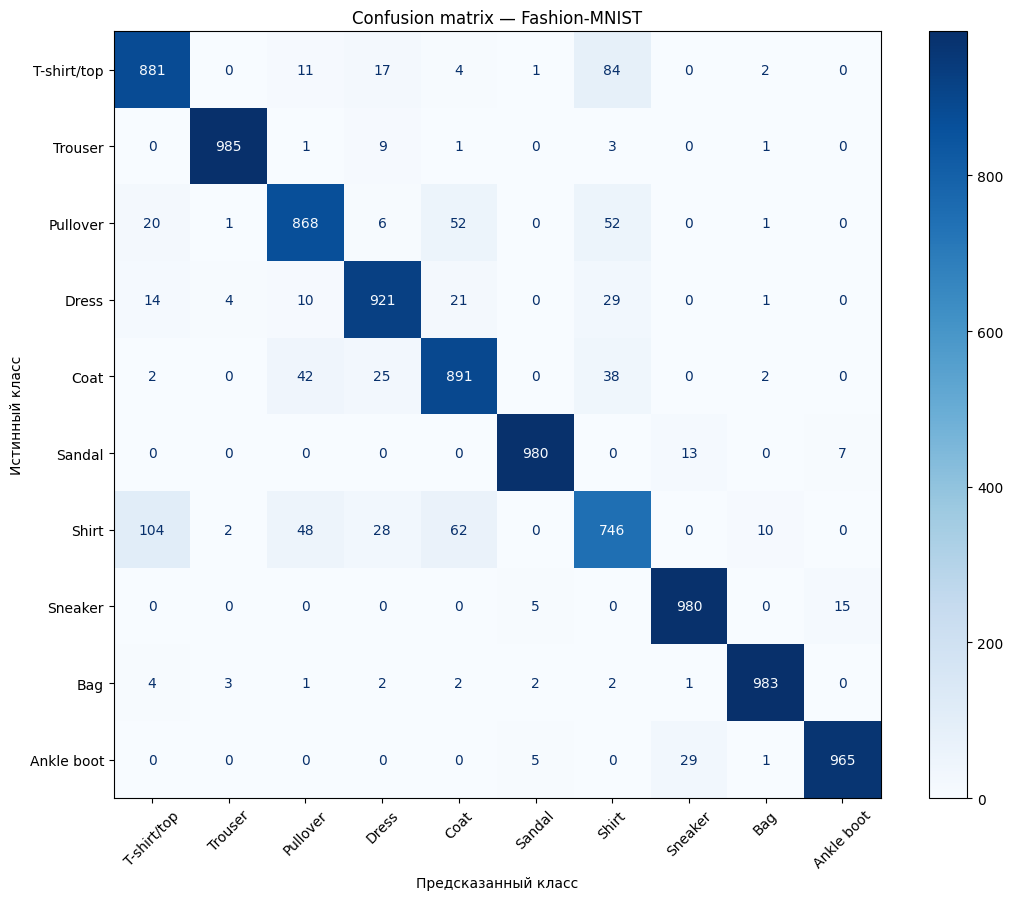

Изображение сохранено в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\baseline\figures\confusion_matrix.png


In [48]:
from sklearn.metrics import ConfusionMatrixDisplay


figures_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "figures"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)

confusion_png_path = (
    figures_dir
    / "confusion_matrix.png"
)

fig, ax = plt.subplots(
    figsize=(11, 9),
)

display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=True,
)

ax.set_title(
    "Confusion matrix — Fashion-MNIST"
)

ax.set_xlabel(
    "Предсказанный класс"
)

ax.set_ylabel(
    "Истинный класс"
)

fig.tight_layout()

fig.savefig(
    confusion_png_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(
    "Изображение сохранено в:",
    confusion_png_path,
)

In [49]:
#Какой класс распознаётся лучше всего
class_accuracies = []

for class_id, class_name in enumerate(CLASS_NAMES):
    total_samples = confusion[class_id].sum()
    correct_predictions = confusion[
        class_id,
        class_id,
    ]

    accuracy = (
        correct_predictions / total_samples
    )

    class_accuracies.append(accuracy)

best_class_id = int(
    np.argmax(class_accuracies)
)

worst_class_id = int(
    np.argmin(class_accuracies)
)

print(
    "Лучше всего распознаётся:",
    CLASS_NAMES[best_class_id],
    class_accuracies[best_class_id],
)

print(
    "Хуже всего распознаётся:",
    CLASS_NAMES[worst_class_id],
    class_accuracies[worst_class_id],
)

Лучше всего распознаётся: Trouser 0.985
Хуже всего распознаётся: Shirt 0.746


In [50]:
#какие классы чаще всего путаются
pair_errors = []

num_classes = len(CLASS_NAMES)

for first_class in range(num_classes):
    for second_class in range(
        first_class + 1,
        num_classes,
    ):
        errors = (
            confusion[first_class, second_class]
            + confusion[second_class, first_class]
        )

        pair_errors.append(
            {
                "first_class": first_class,
                "second_class": second_class,
                "errors": int(errors),
            }
        )

most_confused_pair = max(
    pair_errors,
    key=lambda item: item["errors"],
)

first_class = most_confused_pair["first_class"]
second_class = most_confused_pair["second_class"]

print(
    "Чаще всего путаются:",
    CLASS_NAMES[first_class],
    "и",
    CLASS_NAMES[second_class],
)

print(
    "Количество ошибок в обе стороны:",
    most_confused_pair["errors"],
)

Чаще всего путаются: T-shirt/top и Shirt
Количество ошибок в обе стороны: 188


In [51]:
#Направление основной ошибки для каждого класса
for class_id, class_name in enumerate(CLASS_NAMES):
    errors = confusion[class_id].copy()

    # Убираем правильные предсказания
    errors[class_id] = 0

    most_common_wrong_class = int(
        np.argmax(errors)
    )

    print(
        f"{class_name} чаще всего принимает "
        f"за {CLASS_NAMES[most_common_wrong_class]}: "
        f"{errors[most_common_wrong_class]} раз"
    )

T-shirt/top чаще всего принимает за Shirt: 84 раз
Trouser чаще всего принимает за Dress: 9 раз
Pullover чаще всего принимает за Coat: 52 раз
Dress чаще всего принимает за Shirt: 29 раз
Coat чаще всего принимает за Pullover: 42 раз
Sandal чаще всего принимает за Sneaker: 13 раз
Shirt чаще всего принимает за T-shirt/top: 104 раз
Sneaker чаще всего принимает за Ankle boot: 15 раз
Bag чаще всего принимает за T-shirt/top: 4 раз
Ankle boot чаще всего принимает за Sneaker: 29 раз


In [52]:
#Проверка симметричности ошибок
is_symmetric = np.array_equal(
    confusion,
    confusion.T,
)

print(
    "Матрица полностью симметрична:",
    is_symmetric,
)

Матрица полностью симметрична: False


In [53]:
max_difference = 0
most_asymmetric_pair = None

for first_class in range(num_classes):
    for second_class in range(
        first_class + 1,
        num_classes,
    ):
        difference = abs(
            confusion[first_class, second_class]
            - confusion[second_class, first_class]
        )

        if difference > max_difference:
            max_difference = difference
            most_asymmetric_pair = (
                first_class,
                second_class,
            )

first_class, second_class = most_asymmetric_pair

print(
    "Наиболее несимметричная пара:",
    CLASS_NAMES[first_class],
    "и",
    CLASS_NAMES[second_class],
)

print(
    f"{CLASS_NAMES[first_class]} → "
    f"{CLASS_NAMES[second_class]}:",
    confusion[first_class, second_class],
)

print(
    f"{CLASS_NAMES[second_class]} → "
    f"{CLASS_NAMES[first_class]}:",
    confusion[second_class, first_class],
)

Наиболее несимметричная пара: Coat и Shirt
Coat → Shirt: 38
Shirt → Coat: 62


Для полной выборки Fashion-MNIST используется CNN с фиксированной архитектурой, оптимизатор Adam и функция потерь CrossEntropyLoss. Обучение проводится в два этапа: сначала с исходным learning rate, затем с уменьшенным в 10 раз. На каждом этапе используется остановка по отсутствию улучшения Validation Loss в течение 10 эпох.

Checkpoint полной модели выбирается по минимальному Validation Loss. Актуальные значения Validation Loss, Validation Accuracy, Test Accuracy, Macro-F1 и метрики по классам сохраняются в папке experiments/fashion_mnist/baseline.

Эта модель используется как базовая точка для дальнейшего сравнения с F-A и моделями, обученными на дополненных наборах данных.

### 16. Разделение train на F-A и F-B

In [54]:
from sklearn.model_selection import train_test_split


fa_experiment_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "fa_fb"
)

fa_experiment_root.mkdir(
    parents=True,
    exist_ok=True,
)

# Метки исходной полной обучающей выборки
full_targets = (
    full_train_dataset.targets
    .cpu()
    .numpy()
)

# F-A и F-B делим только внутри train
source_train_indices = np.asarray(
    train_indices,
    dtype=np.int64,
)

source_train_targets = full_targets[
    source_train_indices
]

fa_indices, fb_indices = train_test_split(
    source_train_indices,
    train_size=0.20,
    test_size=0.80,
    stratify=source_train_targets,
    random_state=SEED,
)

fa_indices = np.asarray(
    fa_indices,
    dtype=np.int64,
)

fb_indices = np.asarray(
    fb_indices,
    dtype=np.int64,
)

In [55]:
#Проверка размеров и пересечений
assert len(fa_indices) == 10800
assert len(fb_indices) == 43200

assert len(
    np.intersect1d(
        fa_indices,
        fb_indices,
    )
) == 0

combined_indices = np.concatenate(
    [fa_indices, fb_indices]
)

assert set(combined_indices) == set(
    source_train_indices
)

print("Размер F-A:", len(fa_indices))
print("Размер F-B:", len(fb_indices))
print("Размер validation:", len(validation_indices))
print("Размер test:", len(test_dataset))
print("F-A и F-B не пересекаются")

Размер F-A: 10800
Размер F-B: 43200
Размер validation: 6000
Размер test: 10000
F-A и F-B не пересекаются


In [56]:
#Проверка распределения классов
fa_class_counts = np.bincount(
    full_targets[fa_indices],
    minlength=len(CLASS_NAMES),
)

fb_class_counts = np.bincount(
    full_targets[fb_indices],
    minlength=len(CLASS_NAMES),
)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_id}: {class_name:12s} | "
        f"F-A = {fa_class_counts[class_id]:4d} | "
        f"F-B = {fb_class_counts[class_id]:4d}"
    )

0: T-shirt/top  | F-A = 1080 | F-B = 4320
1: Trouser      | F-A = 1080 | F-B = 4320
2: Pullover     | F-A = 1080 | F-B = 4320
3: Dress        | F-A = 1080 | F-B = 4320
4: Coat         | F-A = 1080 | F-B = 4320
5: Sandal       | F-A = 1080 | F-B = 4320
6: Shirt        | F-A = 1080 | F-B = 4320
7: Sneaker      | F-A = 1080 | F-B = 4320
8: Bag          | F-A = 1080 | F-B = 4320
9: Ankle boot   | F-A = 1080 | F-B = 4320


In [57]:
#Сохраним индексы
split_indices_path = (
    fa_experiment_root
    / "split_indices.npz"
)

np.savez(
    split_indices_path,
    fa_indices=fa_indices,
    fb_indices=fb_indices,
    validation_indices=validation_indices,
    test_indices=np.arange(
        len(test_dataset)
    ),
)

In [58]:
split_metadata = {
    "seed": int(SEED),
    "source_split": "original train split",
    "source_train_size": int(
        len(source_train_indices)
    ),
    "fa_size": int(len(fa_indices)),
    "fb_size": int(len(fb_indices)),
    "fa_fraction": 0.20,
    "fb_fraction": 0.80,
    "validation_size": int(
        len(validation_indices)
    ),
    "test_size": int(len(test_dataset)),
    "stratified": True,
}

split_metadata_path = (
    fa_experiment_root
    / "split_metadata.json"
)

split_metadata_path.write_text(
    json.dumps(
        split_metadata,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Индексы сохранены в:",
    split_indices_path,
)

Индексы сохранены в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\fa_fb\split_indices.npz


### 17. Подготовка датасетов для F-A

In [59]:
#Для нового эксперимента посчитаем нормализацию только по F-A
from copy import copy
from torch.utils.data import Subset


fa_mean, fa_std = calculate_train_mean_std(
    full_train_dataset=full_train_dataset,
    train_indices=fa_indices,
)

print("Среднее F-A:", fa_mean)
print("Стандартное отклонение F-A:", fa_std)

Среднее F-A: 0.28624583872177345
Стандартное отклонение F-A: 0.3536617571752594


In [60]:
#Создадим отдельные копии датасетов, чтобы не менять предыдущий эксперимент
fa_transform = create_normalized_transform(
    mean=fa_mean,
    std=fa_std,
)

fa_parent_dataset = copy(
    full_train_dataset
)

fa_parent_dataset.transform = fa_transform

fa_test_parent_dataset = copy(
    test_dataset
)

fa_test_parent_dataset.transform = fa_transform

In [61]:
#Создадим F-A, F-B и validation
fa_dataset = Subset(
    fa_parent_dataset,
    fa_indices.tolist(),
)

fb_dataset = Subset(
    fa_parent_dataset,
    fb_indices.tolist(),
)

fa_validation_dataset = Subset(
    fa_parent_dataset,
    validation_indices.tolist(),
)

fa_test_dataset = fa_test_parent_dataset

In [62]:
#Проверим размеры
print("F-A:", len(fa_dataset))
print("F-B:", len(fb_dataset))
print(
    "Validation:",
    len(fa_validation_dataset),
)
print("Test:", len(fa_test_dataset))

F-A: 10800
F-B: 43200
Validation: 6000
Test: 10000


### 18. Обучение CNN только на F-A

In [63]:
from torch.utils.data import DataLoader


fa_train_loader = DataLoader(
    fa_dataset,
    batch_size=training_config["batch_size"],
    shuffle=True,
    num_workers=0,
)

fa_validation_loader = DataLoader(
    fa_validation_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

fa_test_loader = DataLoader(
    fa_test_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

print(
    "Train batches:",
    len(fa_train_loader),
)

print(
    "Validation batches:",
    len(fa_validation_loader),
)

print(
    "Test batches:",
    len(fa_test_loader),
)

Train batches: 85
Validation batches: 47
Test batches: 79


In [64]:
#Создадим отдельную конфигурацию
fa_training_config = {
    **training_config,
    "train_split": "F-A",
    "train_size": len(fa_dataset),
    "validation_size": len(
        fa_validation_dataset
    ),
    "test_size": len(fa_test_dataset),
}

In [65]:
#Пути для нового эксперимента
fa_baseline_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "fa_baseline"
)

fa_checkpoint_path = (
    fa_baseline_root
    / "checkpoints"
    / "best_model.pt"
)

fa_history_path = (
    fa_baseline_root
    / "history.json"
)

In [66]:
#Метаданные нового checkpoint
fa_normalization_config = {
    "mean": float(fa_mean),
    "std": float(fa_std),
    "calculated_from": "F-A only",
}

fa_checkpoint_metadata = {
    "experiment": "F-A baseline",
    "seed": int(SEED),
    "normalization": fa_normalization_config,
    "architecture": architecture_config,
    "training": fa_training_config,
    "dataset_sizes": {
        "train": len(fa_dataset),
        "validation": len(
            fa_validation_dataset
        ),
        "test": len(fa_test_dataset),
        "fb_reserved": len(fb_dataset),
    },
}

In [67]:
import importlib

import src.train as train_module

# Перечитываем изменённый файл src/train.py
importlib.reload(train_module)

from src.train import fit_two_stage


# Фиксируем seed для воспроизводимости
set_seed(SEED)


# Создаём модель F-A с нуля
fa_model = FashionCNN(
    dropout=fa_training_config["dropout"]
).to(device)


fa_criterion = nn.CrossEntropyLoss()


fa_optimizer = torch.optim.Adam(
    fa_model.parameters(),
    lr=fa_training_config[
        "learning_rate"
    ],
    weight_decay=fa_training_config[
        "weight_decay"
    ],
)


In [68]:
# Двухэтапное обучение F-A
fa_history = fit_two_stage(
    model=fa_model,
    train_loader=fa_train_loader,
    validation_loader=fa_validation_loader,
    criterion=fa_criterion,
    optimizer=fa_optimizer,
    device=device,
    epochs=fa_training_config[
        "epochs"
    ],
    patience=fa_training_config[
        "early_stopping_patience"
    ],
    min_delta=fa_training_config[
        "min_delta"
    ],
    lr_factor=fa_training_config[
        "learning_rate_factor"
    ],
    checkpoint_path=fa_checkpoint_path,
    history_path=fa_history_path,
    checkpoint_metadata=fa_checkpoint_metadata,
)

Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.8134 | train accuracy: 0.7191 | validation loss: 0.4715 | validation accuracy: 0.8378
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.4905 | train accuracy: 0.8287 | validation loss: 0.3942 | validation accuracy: 0.8637
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.4075 | train accuracy: 0.8604 | validation loss: 0.3636 | validation accuracy: 0.8672
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.3663 | train accuracy: 0.8704 | validation loss: 0.3424 | validation accuracy: 0.8743
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.3271 | train accuracy: 0.8849 | validation loss: 0.3227 | validation accuracy: 0.8855
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.2972 | train accuracy: 0.8932 | validation loss: 0.3065 | validation accuracy: 0.8892
Stage 1 | Epoch 007 | lr: 0.001000 | train loss: 0.2785 | train accuracy: 0.9015 | validation loss: 0.2939 | validation accuracy: 0.8955
Stage 1 | Epoch 008 | lr: 0.001000 | trai

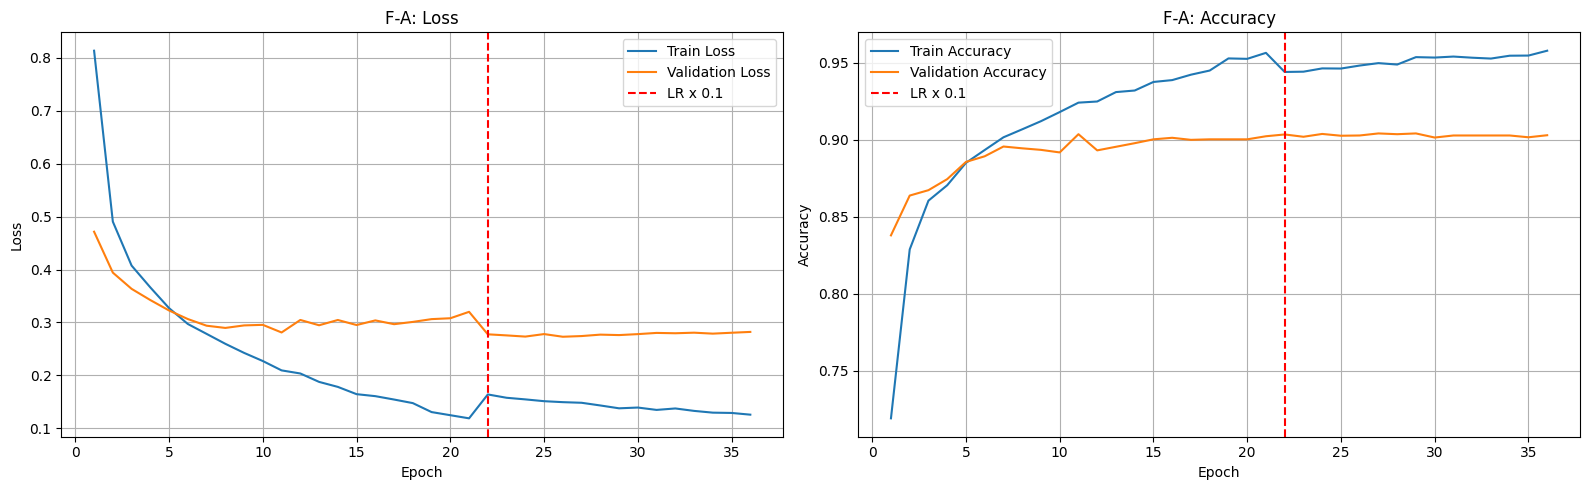

График сохранён: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\fa_baseline\figures\training_curves.png


In [69]:
import matplotlib.pyplot as plt


fa_epochs = fa_history["epoch"]
fa_stages = fa_history["stage"]


fa_training_curves_path = (
    fa_baseline_root
    / "figures"
    / "training_curves.png"
)

fa_training_curves_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)


fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 5),
)


# График Loss
axes[0].plot(
    fa_epochs,
    fa_history["train_loss"],
    label="Train Loss",
)

axes[0].plot(
    fa_epochs,
    fa_history["validation_loss"],
    label="Validation Loss",
)


# Находим начало второго этапа
stage_2_epochs = [
    epoch
    for epoch, stage in zip(
        fa_epochs,
        fa_stages,
    )
    if stage == 2
]


if len(stage_2_epochs) > 0:
    stage_2_start = stage_2_epochs[0]

    axes[0].axvline(
        stage_2_start,
        color="red",
        linestyle="--",
        label="LR x 0.1",
    )


axes[0].set_title(
    "F-A: Loss"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Loss"
)

axes[0].legend()
axes[0].grid()


# График Accuracy
axes[1].plot(
    fa_epochs,
    fa_history["train_accuracy"],
    label="Train Accuracy",
)

axes[1].plot(
    fa_epochs,
    fa_history["validation_accuracy"],
    label="Validation Accuracy",
)

if len(stage_2_epochs) > 0:
    axes[1].axvline(
        stage_2_start,
        color="red",
        linestyle="--",
        label="LR x 0.1",
    )


axes[1].set_title(
    "F-A: Accuracy"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Accuracy"
)

axes[1].legend()
axes[1].grid()


plt.tight_layout()


fig.savefig(
    fa_training_curves_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


print(
    "График сохранён:",
    fa_training_curves_path,
)

### 19. Итоговая оценка F-A модели

In [70]:
import csv
import json
from pathlib import Path

import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
)


# Загружаем лучший checkpoint
fa_checkpoint = torch.load(
    fa_checkpoint_path,
    map_location=device,
)


# Создаём модель для оценки
fa_best_model = FashionCNN(
    dropout=fa_training_config["dropout"]
).to(device)


fa_best_model.load_state_dict(
    fa_checkpoint[
        "model_state_dict"
    ]
)

fa_best_model.eval()


# Для расчёта метрик train
# используем shuffle=False
fa_train_eval_loader = DataLoader(
    fa_dataset,
    batch_size=fa_training_config[
        "batch_size"
    ],
    shuffle=False,
    num_workers=0,
)


def collect_predictions(
    model,
    data_loader,
    device,
):
    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)

            logits = model(images)

            predictions = logits.argmax(
                dim=1
            )

            all_labels.append(
                labels.cpu()
            )

            all_predictions.append(
                predictions.cpu()
            )

    y_true = torch.cat(
        all_labels
    ).numpy()

    y_pred = torch.cat(
        all_predictions
    ).numpy()

    return y_true, y_pred


# Предсказания на трёх выборках
fa_train_y_true, fa_train_y_pred = (
    collect_predictions(
        model=fa_best_model,
        data_loader=fa_train_eval_loader,
        device=device,
    )
)


fa_validation_y_true, fa_validation_y_pred = (
    collect_predictions(
        model=fa_best_model,
        data_loader=fa_validation_loader,
        device=device,
    )
)


fa_test_y_true, fa_test_y_pred = (
    collect_predictions(
        model=fa_best_model,
        data_loader=fa_test_loader,
        device=device,
    )
)


# Оставляем старые имена переменных,
# чтобы последующие ячейки не сломались
fa_y_true = fa_test_y_true
fa_y_pred = fa_test_y_pred


def calculate_per_class_metrics(
    y_true,
    y_pred,
    class_names,
):
    confusion = confusion_matrix(
        y_true,
        y_pred,
        labels=list(
            range(len(class_names))
        ),
    )

    total_samples = int(
        confusion.sum()
    )

    rows = []

    for class_id, class_name in enumerate(
        class_names
    ):
        true_positive = int(
            confusion[
                class_id,
                class_id,
            ]
        )

        false_negative = int(
            confusion[class_id, :].sum()
            - true_positive
        )

        false_positive = int(
            confusion[:, class_id].sum()
            - true_positive
        )

        true_negative = int(
            total_samples
            - true_positive
            - false_negative
            - false_positive
        )

        support = (
            true_positive
            + false_negative
        )

        recall = (
            true_positive / support
            if support > 0
            else 0.0
        )

        accuracy = (
            (true_positive + true_negative)
            / total_samples
            if total_samples > 0
            else 0.0
        )

        rows.append(
            {
                "class_id": class_id,
                "class_name": class_name,
                "recall": float(recall),
                "accuracy": float(accuracy),
                "support": int(support),
                "true_positive": true_positive,
                "false_positive": false_positive,
                "false_negative": false_negative,
            }
        )

    return confusion, rows


def save_per_class_metrics(
    rows,
    output_path,
):
    output_path = Path(output_path)
    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    fieldnames = [
        "class_id",
        "class_name",
        "recall",
        "accuracy",
        "support",
        "true_positive",
        "false_positive",
        "false_negative",
    ]

    with output_path.open(
        "w",
        newline="",
        encoding="utf-8",
    ) as csv_file:
        writer = csv.DictWriter(
            csv_file,
            fieldnames=fieldnames,
        )

        writer.writeheader()
        writer.writerows(rows)


fa_metrics_dir = (
    fa_baseline_root
    / "metrics"
)

fa_metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# Train
fa_train_confusion, fa_train_rows = (
    calculate_per_class_metrics(
        fa_train_y_true,
        fa_train_y_pred,
        CLASS_NAMES,
    )
)


save_per_class_metrics(
    fa_train_rows,
    fa_metrics_dir
    / "train_per_class_metrics.csv",
)


# Validation
fa_validation_confusion, fa_validation_rows = (
    calculate_per_class_metrics(
        fa_validation_y_true,
        fa_validation_y_pred,
        CLASS_NAMES,
    )
)


save_per_class_metrics(
    fa_validation_rows,
    fa_metrics_dir
    / "validation_per_class_metrics.csv",
)


# Test
fa_test_confusion, fa_test_rows = (
    calculate_per_class_metrics(
        fa_test_y_true,
        fa_test_y_pred,
        CLASS_NAMES,
    )
)


save_per_class_metrics(
    fa_test_rows,
    fa_metrics_dir
    / "test_per_class_metrics.csv",
)


# Общие test-метрики
fa_test_accuracy = accuracy_score(
    fa_test_y_true,
    fa_test_y_pred,
)


fa_macro_f1 = f1_score(
    fa_test_y_true,
    fa_test_y_pred,
    average="macro",
    zero_division=0,
)


fa_test_metrics = {
    "experiment": "F-A baseline",
    "train_size": len(fa_dataset),
    "validation_size": len(
        fa_validation_dataset
    ),
    "test_size": len(
        fa_test_dataset
    ),
    "checkpoint_epoch": int(
        fa_checkpoint["epoch"]
    ),
    "checkpoint_stage": int(
        fa_checkpoint["stage"]
    ),
    "validation_loss": float(
        fa_checkpoint["validation_loss"]
    ),
    "validation_accuracy": float(
        fa_checkpoint["validation_accuracy"]
    ),
    "test_accuracy": float(
        fa_test_accuracy
    ),
    "macro_f1": float(
        fa_macro_f1
    ),
    "seed": int(SEED),
}


fa_test_metrics_path = (
    fa_metrics_dir
    / "test_metrics.json"
)


fa_test_metrics_path.write_text(
    json.dumps(
        fa_test_metrics,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# Сохраняем test confusion matrix
fa_confusion_csv_path = (
    fa_metrics_dir
    / "confusion_matrix.csv"
)


with fa_confusion_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    writer = csv.writer(csv_file)

    writer.writerow(
        ["true_class"]
        + list(CLASS_NAMES)
    )

    for class_name, row in zip(
        CLASS_NAMES,
        fa_test_confusion,
    ):
        writer.writerow(
            [class_name]
            + row.tolist()
        )


print("F-A метрики сохранены.")
print()
print("Test accuracy:", fa_test_accuracy)
print("Macro-F1:", fa_macro_f1)
print()
print(
    "Checkpoint epoch:",
    fa_checkpoint["epoch"],
)
print(
    "Checkpoint stage:",
    fa_checkpoint["stage"],
)
print(
    "Validation Loss:",
    fa_checkpoint["validation_loss"],
)

F-A метрики сохранены.

Test accuracy: 0.893
Macro-F1: 0.892674991620833

Checkpoint epoch: 26
Checkpoint stage: 2
Validation Loss: 0.27308361188570657


F-A используется как базовая модель для эксперимента с ограниченным количеством реальных обучающих данных. Исходная обучающая выборка разделена на F-A и F-B стратифицированно, с фиксированным seed. F-A содержит 10 800 изображений, а F-B используется как резервный набор. Validation и test-выборки остаются отдельными.

Модель F-A обучается по той же двухэтапной схеме, что и полная модель: с early stopping по Validation Loss и уменьшением learning rate в 10 раз после первого этапа. Checkpoint выбирается по минимальному Validation Loss.

Актуальные результаты F-A сохраняются в папке experiments/fashion_mnist/fa_baseline и используются как базовая точка перед реализацией стратегий добавления изображений.

На данном этапе были обучены и оценены две CNN-модели: модель на полной обучающей выборке F и модель на сокращённой выборке F-A. Для обеих моделей использовались одинаковая архитектура, двухэтапная схема обучения, early stopping по Validation Loss и уменьшение learning rate в 10 раз на втором этапе.

Модель F показала Test Accuracy 0,9200 и Macro-F1 0,9197. Для модели F-A Test Accuracy составила 0,8930, а Macro-F1 — 0,8927. Таким образом, сокращение обучающей выборки привело к снижению Accuracy примерно на 2,70 процентного пункта, а Macro-F1 — примерно на 2,71 процентного пункта.

Наибольшие трудности у обеих моделей возникают при распознавании класса Shirt. Суммарное количество ошибок между классами T-shirt/top и Shirt составило 188 для модели F и 223 для модели F-A. Это подтверждает, что увеличение объёма обучающих данных улучшает качество классификации и уменьшает количество ошибок между наиболее сложными классами.

Полученные модели F и F-A зафиксированы как базовые точки для дальнейшего эксперимента со стратегиями отбора и добавления новых изображений из F-B.

### 20. Настройки проверки устойчивости

In [71]:
# 20. Проверка устойчивости ошибок
# Модели с разными случайными инициализациями

from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from src.model import FashionCNN
from src.train import fit_two_stage


# Количество независимых запусков CNN
STABILITY_RUNS = 5

# Разные seed для разных запусков
STABILITY_SEEDS = [
    SEED + run_id
    for run_id in range(STABILITY_RUNS)
]

# Контрольная выборка.
# Test здесь не используется.
CONTROL_DATASET = fa_validation_dataset
CONTROL_ORIGINAL_INDICES = np.asarray(
    validation_indices,
    dtype=np.int64,
)

CONTROL_DATASET_NAME = "F-A validation"


# Папка для результатов
stability_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "model_stability"
)

stability_root.mkdir(
    parents=True,
    exist_ok=True,
)


assert len(CONTROL_DATASET) == len(
    CONTROL_ORIGINAL_INDICES
)

print(
    "Контрольная выборка:",
    CONTROL_DATASET_NAME,
)

print(
    "Размер контрольной выборки:",
    len(CONTROL_DATASET),
)

print(
    "Количество запусков CNN:",
    STABILITY_RUNS,
)

print(
    "Seed запусков:",
    STABILITY_SEEDS,
)

print(
    "Устройство:",
    device,
)

Контрольная выборка: F-A validation
Размер контрольной выборки: 6000
Количество запусков CNN: 5
Seed запусков: [42, 43, 44, 45, 46]
Устройство: cuda


### 21. Вспомогательные функции

In [72]:
def create_stability_loader(
    dataset,
    shuffle,
    seed=None,
):
    """
    Создаёт DataLoader.

    Для train используется отдельный generator
    каждого запуска, чтобы порядок батчей также
    зависел от seed.
    """

    generator = torch.Generator()

    if seed is not None:
        generator.manual_seed(int(seed))

    return DataLoader(
        dataset,
        batch_size=fa_training_config["batch_size"],
        shuffle=shuffle,
        num_workers=0,
        generator=generator,
    )


def collect_control_predictions(
    model,
    data_loader,
    device,
):
    """
    Получает истинные классы и предсказания
    модели на контрольной выборке.
    """

    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)

            logits = model(images)

            predictions = logits.argmax(
                dim=1
            )

            all_labels.append(
                labels.detach()
                .cpu()
                .numpy()
            )

            all_predictions.append(
                predictions.detach()
                .cpu()
                .numpy()
            )

    labels = np.concatenate(
        all_labels
    )

    predictions = np.concatenate(
        all_predictions
    )

    return labels, predictions


def create_fa_stability_model():
    """
    Создаёт CNN с той же архитектурой,
    что и базовая модель F-A.
    """

    return FashionCNN(
        dropout=fa_training_config[
            "dropout"
        ]
    ).to(device)

### 22. Обучение пяти независимых моделей

In [73]:
run_summaries = []

all_error_vectors = []

control_labels_reference = None


for run_number, run_seed in enumerate(
    STABILITY_SEEDS,
    start=1,
):
    print()
    print("=" * 70)
    print(
        f"Запуск CNN {run_number}/{STABILITY_RUNS}"
    )
    print("Seed:", run_seed)
    print("=" * 70)

    # Фиксируем seed до создания модели
    # и DataLoader
    set_seed(run_seed)

    run_root = (
        stability_root
        / f"run_{run_number:02d}"
    )

    checkpoint_path = (
        run_root
        / "checkpoints"
        / "best_model.pt"
    )

    history_path = (
        run_root
        / "history.json"
    )

    train_loader = (
        create_stability_loader(
            dataset=fa_dataset,
            shuffle=True,
            seed=run_seed,
        )
    )

    control_loader = (
        create_stability_loader(
            dataset=CONTROL_DATASET,
            shuffle=False,
            seed=run_seed,
        )
    )

    model = create_fa_stability_model()

    criterion = torch.nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=fa_training_config[
            "learning_rate"
        ],
        weight_decay=fa_training_config[
            "weight_decay"
        ],
    )

    checkpoint_metadata = {
        "experiment": (
            "F-A model stability check"
        ),
        "stability_run": int(
            run_number
        ),
        "seed": int(run_seed),
        "control_dataset": (
            CONTROL_DATASET_NAME
        ),
        "normalization": (
            fa_normalization_config
        ),
        "architecture": (
            architecture_config
        ),
        "training": (
            fa_training_config
        ),
        "dataset_sizes": {
            "train": len(fa_dataset),
            "control": len(
                CONTROL_DATASET
            ),
        },
    }

    # Обучение выполняется по той же схеме,
    # что и базовая модель F-A:
    # 100 эпох максимум,
    # early stopping,
    # уменьшение learning rate в 10 раз
    history = fit_two_stage(
        model=model,
        train_loader=train_loader,
        validation_loader=control_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        epochs=fa_training_config[
            "epochs"
        ],
        patience=fa_training_config[
            "early_stopping_patience"
        ],
        min_delta=fa_training_config[
            "min_delta"
        ],
        lr_factor=fa_training_config[
            "learning_rate_factor"
        ],
        checkpoint_path=checkpoint_path,
        history_path=history_path,
        checkpoint_metadata=(
            checkpoint_metadata
        ),
    )

    # Загружаем лучший checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
    )

    best_model = (
        create_fa_stability_model()
    )

    best_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    best_model.eval()

    # Предсказания на одной и той же
    # контрольной выборке
    labels, predictions = (
        collect_control_predictions(
            model=best_model,
            data_loader=control_loader,
            device=device,
        )
    )

    # Проверяем, что порядок и метки
    # во всех запусках одинаковые
    if control_labels_reference is None:
        control_labels_reference = (
            labels.copy()
        )
    else:
        assert np.array_equal(
            control_labels_reference,
            labels,
        ), (
            "Метки контрольной выборки "
            "отличаются между запусками."
        )

    # Ошибка для каждого изображения:
    # 1 — модель ошиблась,
    # 0 — модель классифицировала правильно
    error_vector = (
        predictions != labels
    ).astype(np.int8)

    all_error_vectors.append(
        error_vector
    )

    control_accuracy = float(
        np.mean(predictions == labels)
    )

    run_summaries.append(
        {
            "run": int(run_number),
            "seed": int(run_seed),
            "best_epoch": int(
                checkpoint["epoch"]
            ),
            "best_stage": int(
                checkpoint["stage"]
            ),
            "validation_loss": float(
                checkpoint[
                    "validation_loss"
                ]
            ),
            "validation_accuracy": float(
                checkpoint[
                    "validation_accuracy"
                ]
            ),
            "control_accuracy": (
                control_accuracy
            ),
            "error_count": int(
                error_vector.sum()
            ),
        }
    )

    print()
    print(
        "Лучший этап:",
        checkpoint["stage"],
    )

    print(
        "Лучшая эпоха:",
        checkpoint["epoch"],
    )

    print(
        "Control accuracy:",
        control_accuracy,
    )

    print(
        "Количество ошибок:",
        int(error_vector.sum()),
    )

    del model
    del best_model

    if device.type == "cuda":
        torch.cuda.empty_cache()


# Возвращаем основной seed
set_seed(SEED)

print()
print("Все независимые запуски завершены.")


Запуск CNN 1/5
Seed: 42
Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.7889 | train accuracy: 0.7227 | validation loss: 0.4566 | validation accuracy: 0.8382
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.4644 | train accuracy: 0.8367 | validation loss: 0.3683 | validation accuracy: 0.8698
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.4034 | train accuracy: 0.8565 | validation loss: 0.3347 | validation accuracy: 0.8803
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.3574 | train accuracy: 0.8731 | validation loss: 0.3352 | validation accuracy: 0.8812
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.3256 | train accuracy: 0.8831 | validation loss: 0.3120 | validation accuracy: 0.8877
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.2987 | train accuracy: 0.8921 | validation loss: 0.3238 | validation accuracy: 0.8808
Stage 1 | Epoch 007 | lr: 0.001000 | train loss: 0.2734 | train accuracy: 0.9049 | validation loss: 0.3134 | validation accuracy: 0.8885
Stage 1 | Epoch 

### 23. Расчёт q(x)

In [74]:
# Матрица ошибок:
# строки — запуски CNN,
# столбцы — изображения контрольной выборки

error_matrix = np.stack(
    all_error_vectors,
    axis=0,
)

control_labels = (
    control_labels_reference
)

assert error_matrix.shape == (
    STABILITY_RUNS,
    len(CONTROL_DATASET),
)


# Количество моделей, ошибшихся
# на каждом изображении
error_count_per_image = (
    error_matrix.sum(axis=0)
)


# q(x) — доля моделей,
# ошибшихся на изображении x
q_per_image = (
    error_count_per_image
    / STABILITY_RUNS
)


# Множество S:
# изображения, на которых ошиблась
# хотя бы одна модель
has_any_error = (
    error_count_per_image > 0
)

s_size = int(
    has_any_error.sum()
)

print(
    "Размер множества S:",
    s_size,
)

print(
    "Всего изображений:",
    len(CONTROL_DATASET),
)

print(
    "Минимальное q(x) среди S:",
    q_per_image[
        has_any_error
    ].min()
    if s_size > 0
    else None,
)

print(
    "Максимальное q(x) среди S:",
    q_per_image[
        has_any_error
    ].max()
    if s_size > 0
    else None,
)

print(
    "Среднее q(x) по S:",
    q_per_image[
        has_any_error
    ].mean()
    if s_size > 0
    else None,
)

Размер множества S: 947
Всего изображений: 6000
Минимальное q(x) среди S: 0.2
Максимальное q(x) среди S: 1.0
Среднее q(x) по S: 0.6097148891235481


### 24. Среднее значение q по классам

In [75]:
q_by_class = []

for class_id, class_name in enumerate(
    CLASS_NAMES
):
    class_mask = (
        control_labels == class_id
    )

    # S для конкретного класса:
    # изображения класса, где ошиблась
    # хотя бы одна модель
    class_error_mask = (
        class_mask
        & has_any_error
    )

    class_q_values = q_per_image[
        class_error_mask
    ]

    if len(class_q_values) > 0:
        q_average = float(
            class_q_values.mean()
        )
    else:
        q_average = None

    q_by_class.append(
        {
            "class_id": int(class_id),
            "class_name": class_name,
            "class_size": int(
                class_mask.sum()
            ),
            "errors_in_at_least_one_model": int(
                class_error_mask.sum()
            ),
            "q_average": q_average,
        }
    )


print(
    "Среднее q(x) по классам:"
)

for row in q_by_class:
    print(
        f"{row['class_name']}: "
        f"S = "
        f"{row['errors_in_at_least_one_model']}, "
        f"q_average = "
        f"{row['q_average']}"
    )

Среднее q(x) по классам:
T-shirt/top: S = 129, q_average = 0.5953488372093024
Trouser: S = 17, q_average = 0.7294117647058824
Pullover: S = 158, q_average = 0.6278481012658227
Dress: S = 94, q_average = 0.6127659574468086
Coat: S = 156, q_average = 0.5884615384615385
Sandal: S = 32, q_average = 0.5375000000000001
Shirt: S = 255, q_average = 0.6352941176470588
Sneaker: S = 44, q_average = 0.4545454545454545
Bag: S = 22, q_average = 0.6454545454545456
Ankle boot: S = 40, q_average = 0.655


### 25. Сохранение результатов

In [76]:
metrics_dir = (
    stability_root / "metrics"
)

figures_dir = (
    stability_root / "figures"
)

metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# Сохраняем результаты каждого запуска
runs_csv_path = (
    metrics_dir / "runs.csv"
)

with runs_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    fieldnames = list(
        run_summaries[0].keys()
    )

    writer = csv.DictWriter(
        csv_file,
        fieldnames=fieldnames,
    )

    writer.writeheader()
    writer.writerows(run_summaries)


# Сохраняем q(x) для каждого изображения
per_image_csv_path = (
    metrics_dir
    / "per_image_error_frequency.csv"
)

image_fieldnames = [
    "dataset_index",
    "label_id",
    "label_name",
    "error_count",
    "q",
]

image_fieldnames.extend(
    [
        f"error_run_{run_id}"
        for run_id in range(
            1,
            STABILITY_RUNS + 1,
        )
    ]
)

with per_image_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    writer = csv.DictWriter(
        csv_file,
        fieldnames=image_fieldnames,
    )

    writer.writeheader()

    for image_position in range(
        len(CONTROL_DATASET)
    ):
        row = {
            "dataset_index": int(
                CONTROL_ORIGINAL_INDICES[
                    image_position
                ]
            ),
            "label_id": int(
                control_labels[
                    image_position
                ]
            ),
            "label_name": CLASS_NAMES[
                int(
                    control_labels[
                        image_position
                    ]
                )
            ],
            "error_count": int(
                error_count_per_image[
                    image_position
                ]
            ),
            "q": float(
                q_per_image[
                    image_position
                ]
            ),
        }

        for run_id in range(
            STABILITY_RUNS
        ):
            row[
                f"error_run_{run_id + 1}"
            ] = int(
                error_matrix[
                    run_id,
                    image_position,
                ]
            )

        writer.writerow(row)


# Сохраняем q_average по классам
class_csv_path = (
    metrics_dir
    / "q_average_by_class.csv"
)

with class_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    fieldnames = list(
        q_by_class[0].keys()
    )

    writer = csv.DictWriter(
        csv_file,
        fieldnames=fieldnames,
    )

    writer.writeheader()
    writer.writerows(q_by_class)


# Сохраняем общую информацию
stability_metadata = {
    "experiment": (
        "Model-independent error check"
    ),
    "runs": int(STABILITY_RUNS),
    "seeds": [
        int(seed)
        for seed in STABILITY_SEEDS
    ],
    "control_dataset": (
        CONTROL_DATASET_NAME
    ),
    "control_size": int(
        len(CONTROL_DATASET)
    ),
    "device": str(device),
    "q_definition": (
        "number of models with error / R"
    ),
    "S_definition": (
        "images with error in at least one model"
    ),
    "runs_summary": run_summaries,
    "q_average_by_class": q_by_class,
}

metadata_path = (
    metrics_dir
    / "stability_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        stability_metadata,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


print()
print(
    "Результаты сохранены в:",
    stability_root,
)


Результаты сохранены в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\model_stability


### 26. График устойчивости ошибок

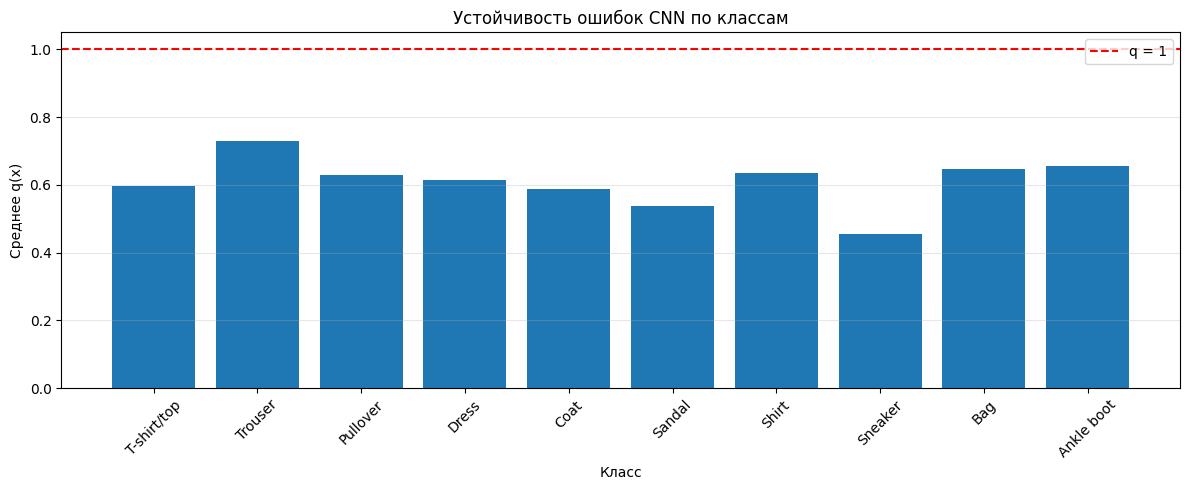

График сохранён в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\model_stability\figures\q_average_by_class.png


In [77]:
valid_q_rows = [
    row
    for row in q_by_class
    if row["q_average"] is not None
]

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.bar(
    [
        row["class_name"]
        for row in valid_q_rows
    ],
    [
        row["q_average"]
        for row in valid_q_rows
    ],
)

ax.axhline(
    1.0,
    color="red",
    linestyle="--",
    label="q = 1",
)

ax.set_ylim(
    0,
    1.05,
)

ax.set_xlabel(
    "Класс"
)

ax.set_ylabel(
    "Среднее q(x)"
)

ax.set_title(
    "Устойчивость ошибок CNN по классам"
)

ax.tick_params(
    axis="x",
    rotation=45,
)

ax.grid(
    axis="y",
    alpha=0.3,
)

ax.legend()

fig.tight_layout()

stability_figure_path = (
    figures_dir
    / "q_average_by_class.png"
)

fig.savefig(
    stability_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(
    "График сохранён в:",
    stability_figure_path,
)